In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

from environments.classes.lindblad_env import Lindblad_Environment
from environments.qm_env_wrapper import GymEnvironment
from sac.train import train
from serialization.serialize_experiment import save_experiment

In [ ]:
seed = 3

Nb = 2
Nc = Nb * 3

steps = 300000

objective = "full"
observation = "diagonal"

ENV_PARAMS = {
    #general
    "wc": 1.0,
    "wb": 1.0,

    "Nc": Nb * 3,
    "Nb": Nb,

    "kappa": 0.2,
    
    "dt": 0.05,
    "tau": 5.6,
}

HYPER_PARAMS = {
    "MIN_U": -0.3,
    "MAX_U": 0.3,

    "USE_STOPPING": True,

    "INITIAL_STOP_PROB": 0.01,

    "STOP_ENTROPY_COEF": 0.0,

    "REWARD": "ergotropy_" + objective,
    "OBSERVATION": observation,

    "REWARD_COEFF": 1.0,

    "BATCH_SIZE": 256,            #batch size

    "LR": 0.001,                  #learning rate for Q and Pi loss
    "ALPHA_LR": 0.003,            #learning rate to tune the temperature parameters alpha 

    "H_START": 0.72,              #initial target entropy of the policy
    "H_END": -3.,                 #final target entropy of the policy
    "H_DECAY": 200000,            #exponential decay of the target entropy of the policy

    "C_START": [0, 1.],           #initial weights for energy and ergotropy to compute the reward (Eqs. S38 - S39)
    "C_END": [0., 1.],            #final weights for energy and ergotropy to compute the reward (Eqs. S38 - S39)
    "C_MEAN": 40000,              #timestep number where the weights are half way between start and end
    "C_WIDTH": 20000,             #width in timesteps to transition from start and end weights        

    "REPLAY_MEMORY_SIZE": 150000, #size of the replay buffer

    "POLYAK": 0.995,              #polyak coefficient

    "GAMMA": 1.0,                 #RL discount factor

    "HIDDEN_SIZES": (512,256),    #size of hidden layers of the neural networks
    
    "INITIAL_RANDOM_STEPS": 5000, #number of initial uniformly random steps
    "UPDATE_AFTER": 1000,         #start minimizing loss function after initial steps
    "UPDATE_EVERY": 50,           #performs this many updates every this many steps

    "USE_CUDA": True,             #use cuda for computation

    "MIN_COV_EIGEN": 1.e-7,       #security parameter for the covariance matrix of the policy

    "USE_LOG" : True,             #log values (if false, PLOT_LOG is implicitely false)
    "LOG_EVERY": 1000,            #interval at which sac params will be logged and plotted

    "PLOT_LOG" : True,            #plot realtime log data
    "PLOT_LOG_FILTER" : [
        "reward",
        "entropy",
        "energy",
        "ergotropy_" + objective,
        "action",
        "stop_probability",
        "stop_entropy",
    ],                            #tags that will be displayed (if empty, will default to all)
}

In [3]:
gym_env = GymEnvironment(
    Lindblad_Environment(params = ENV_PARAMS), 
    HYPER_PARAMS
)

SAC Training:   0%|          | 0/300000 [00:00<?, ?step/s]

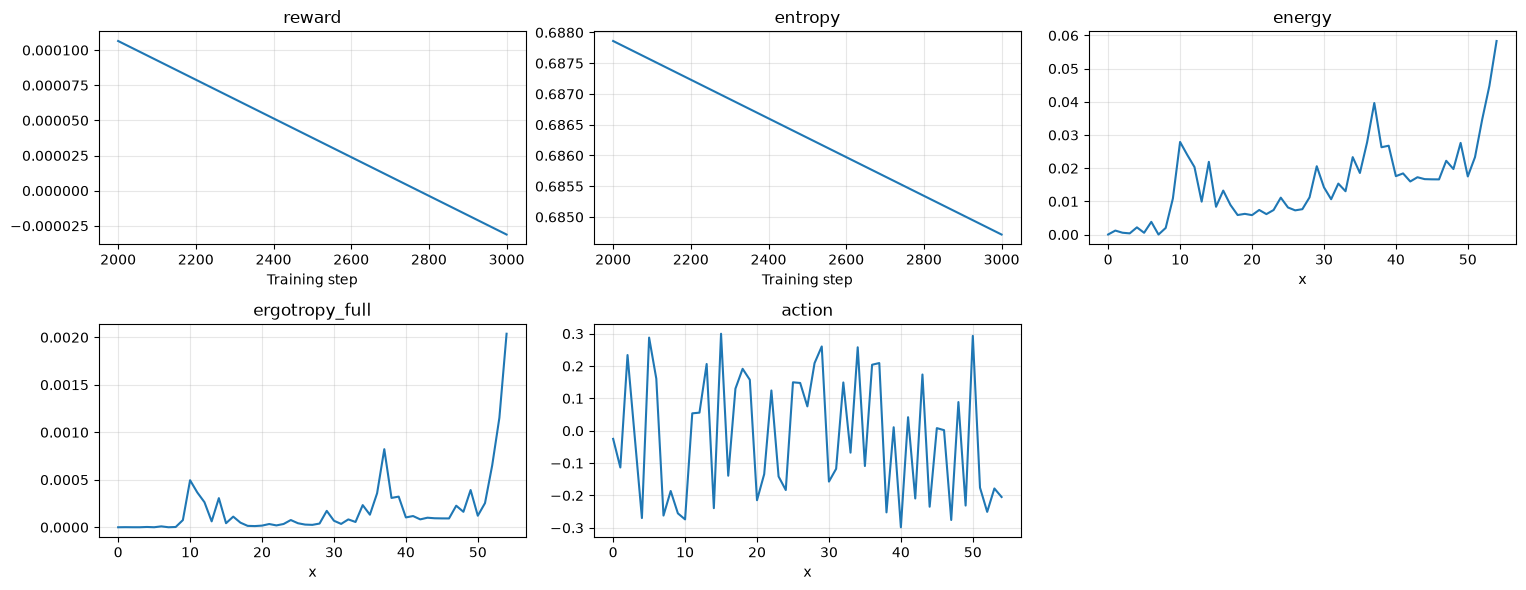

KeyboardInterrupt: 

In [4]:
agent = train(
    gym_env, HYPER_PARAMS, 
    seed = seed, 
    steps = steps
)

In [ ]:
_ = save_experiment(
    agent,
    gym_env,
    env_params=ENV_PARAMS,
    hyper_params=HYPER_PARAMS,
    seed=seed,
    steps=steps,
)

Finished experiment saved: 2026-11-18T14-53-36-457913Z
